# Разделительная кластеризация (k-Means и k-Medoids)

## 1. Формулировка задания
1. Реализовать программу, выполняющую кластеризацию заданного набора данных с помощью алгоритмов k-Means и k-Medoids.
   - Входные параметры: набор данных, количество кластеров k.
   - Выходные данные: координаты точек, назначенные им метки кластеров, значение ошибки кластеризации (Inertia / WCSS / Medoid Total Cost).
2. Эксперименты на чистых данных:
   - Набор данных: `customers.csv` (сведения о клиентах банка).
   - Построение точечных графиков с цветовым отображением кластеров.
   - Построение зависимости ошибки кластеризации от параметра k.
3. Исследование влияния шума:
   - Реализовать функцию зашумления: случайное изменение координат заданной доли объектов (1%, 3%, 5%, 10%).
   - Провести серию экспериментов для k [3-9] при различных долях зашумленных объектов.
   - Визуализировать зависимость ошибки от k и уровня шума.
   - Сравнить устойчивость k-Means и k-Medoids к выбросам и шуму.

## 2. Ссылка на репозиторий
Каталог репозиторий: `https://github.com/GeRoNioPLAY/Data_analysis`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

## 3. Реализация алгоритмов кластеризации и модуля зашумления

In [2]:
class KMedoidsCustom:
    def __init__(self, n_clusters=3, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.medoids_ = None
        self.medoid_indices_ = None
        self.labels_ = None
        self.inertia_ = None

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples = X.shape[0]

        init_idx = np.random.choice(n_samples, self.n_clusters, replace=False)
        self.medoid_indices_ = init_idx.copy()

        dist_matrix = cdist(X, X, metric="euclidean")

        for _ in range(self.max_iter):
            distances_to_medoids = dist_matrix[:, self.medoid_indices_]
            labels = np.argmin(distances_to_medoids, axis=1)

            new_medoids = np.copy(self.medoid_indices_)

            for k in range(self.n_clusters):
                cluster_members = np.where(labels == k)[0]
                if len(cluster_members) == 0:
                    continue
                cluster_subdist = dist_matrix[np.ix_(cluster_members, cluster_members)]
                best_member_idx = cluster_members[
                    np.argmin(cluster_subdist.sum(axis=1))
                ]
                new_medoids[k] = best_member_idx

            if np.array_equal(self.medoid_indices_, new_medoids):
                break
            self.medoid_indices_ = new_medoids

        self.labels_ = labels
        self.medoids_ = X[self.medoid_indices_]

        chosen_dists = dist_matrix[np.arange(n_samples), self.medoid_indices_[labels]]
        self.inertia_ = np.sum(chosen_dists)
        return self


def add_noise(X, noise_ratio=0.05, noise_scale=3.0, random_state=42):
    np.random.seed(random_state)
    X_noisy = X.copy()
    n_samples, n_features = X.shape
    n_noisy = int(np.ceil(n_samples * noise_ratio))

    if n_noisy == 0:
        return X_noisy

    noisy_indices = np.random.choice(n_samples, size=n_noisy, replace=False)

    for idx in noisy_indices:
        n_corrupt_feats = np.random.randint(1, n_features + 1)
        feat_indices = np.random.choice(n_features, size=n_corrupt_feats, replace=False)

        signs = np.random.choice([-1, 1], size=n_corrupt_feats)
        perturbation = signs * np.random.uniform(2.0, noise_scale, size=n_corrupt_feats)
        X_noisy[idx, feat_indices] += perturbation

    return X_noisy

## 4. Загрузка и предобработка данных

In [3]:
df = pd.read_csv("customers.csv")
print("Первые 5 строк исходных данных:")
display(df.head())

drop_cols = [col for col in ["Row", "CustomerId"] if col in df.columns]
features_df = df.drop(columns=drop_cols)

if features_df.isnull().sum().sum() > 0:
    print("\nПропущенные значения в столбцах:")
    print(features_df.isnull().sum())
    features_df = features_df.fillna(features_df.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_df)
feature_names = features_df.columns.tolist()

print(f"\nРазмерность обработанной матрицы признаков: {X_scaled.shape}")
print(f"Используемые признаки: {feature_names}")

Первые 5 строк исходных данных:


,Row,CustomerId,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,Defaulted,DebtIncomeRatio
0,0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,4,5,47,1,31,253,9.308,8.908,0.0,7.2



Пропущенные значения в столбцах:
Age                  0
Education            0
YearsEmployed        0
Income               0
CardDebt             0
OtherDebt            0
Defaulted          150
DebtIncomeRatio      0
dtype: int64

Размерность обработанной матрицы признаков: (850, 8)
Используемые признаки: ['Age', 'Education', 'YearsEmployed', 'Income', 'CardDebt', 'OtherDebt', 'Defaulted', 'DebtIncomeRatio']


## 5. Кластеризация на чистых данных при k = 4

Результаты кластеризации на чистых данных (k = 4)
k-Means:   Ошибка (WCSS) = 3764.03
k-Medoids: Ошибка (Sum of distances) = 1667.49



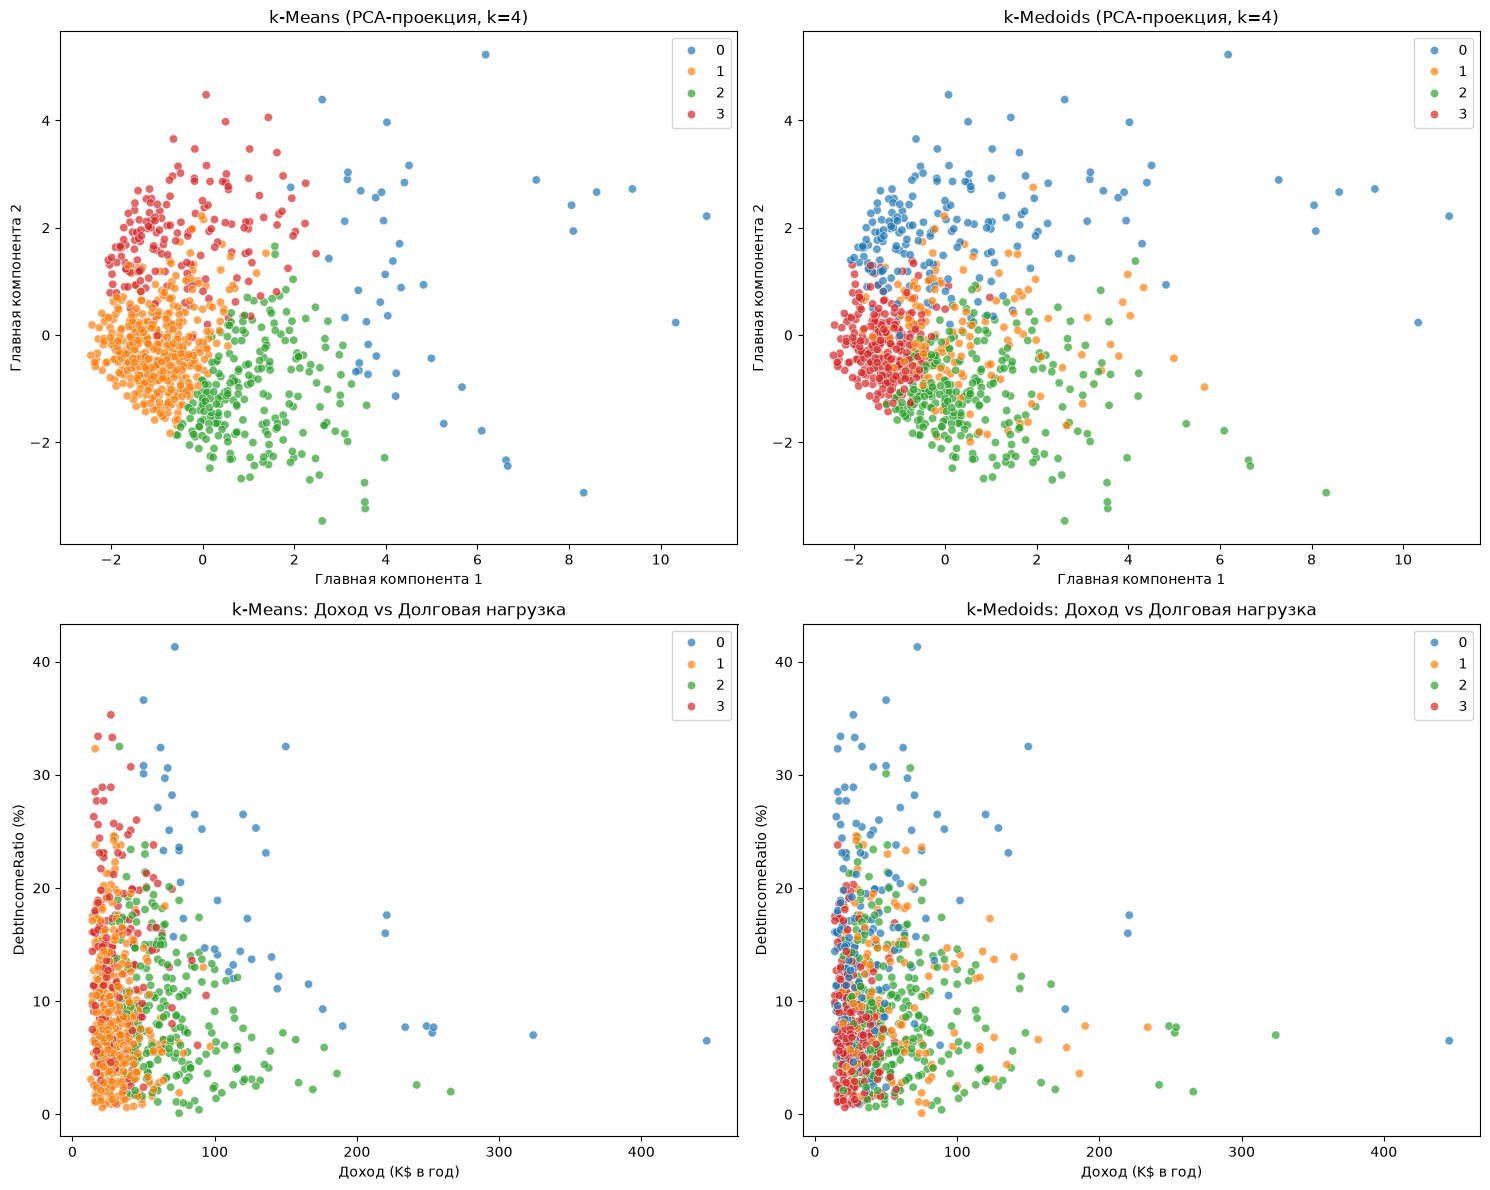

In [ ]:
k_test = 4

kmeans_clean = KMeans(n_clusters=k_test, random_state=42, n_init=10).fit(X_scaled)

kmedoids_clean = KMedoidsCustom(n_clusters=k_test, random_state=42).fit(X_scaled)

print(f"Результаты кластеризации на чистых данных (k = {k_test})")
print(f"k-Means:   Ошибка (WCSS) = {kmeans_clean.inertia_:.2f}")
print(f"k-Medoids: Ошибка (Sum of distances) = {kmedoids_clean.inertia_:.2f}\n")

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_clean.labels_,
    palette="tab10",
    ax=axes[0, 0],
    alpha=0.7,
)
axes[0, 0].set_title(f"k-Means (PCA-проекция, k={k_test})")
axes[0, 0].set_xlabel("Главная компонента 1")
axes[0, 0].set_ylabel("Главная компонента 2")

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmedoids_clean.labels_,
    palette="tab10",
    ax=axes[0, 1],
    alpha=0.7,
)
axes[0, 1].set_title(f"k-Medoids (PCA-проекция, k={k_test})")
axes[0, 1].set_xlabel("Главная компонента 1")
axes[0, 1].set_ylabel("Главная компонента 2")

inc_idx = feature_names.index("Income")
debt_idx = feature_names.index("DebtIncomeRatio")

sns.scatterplot(
    x=features_df["Income"],
    y=features_df["DebtIncomeRatio"],
    hue=kmeans_clean.labels_,
    palette="tab10",
    ax=axes[1, 0],
    alpha=0.7,
)
axes[1, 0].set_title("k-Means: Доход vs Долговая нагрузка")
axes[1, 0].set_xlabel("Доход (K$ в год)")
axes[1, 0].set_ylabel("DebtIncomeRatio (%)")

sns.scatterplot(
    x=features_df["Income"],
    y=features_df["DebtIncomeRatio"],
    hue=kmedoids_clean.labels_,
    palette="tab10",
    ax=axes[1, 1],
    alpha=0.7,
)
axes[1, 1].set_title("k-Medoids: Доход vs Долговая нагрузка")
axes[1, 1].set_xlabel("Доход (K$ в год)")
axes[1, 1].set_ylabel("DebtIncomeRatio (%)")

plt.tight_layout()
plt.show()

In [5]:
results_df = features_df.copy()
results_df["Cluster_kMeans"] = kmeans_clean.labels_
results_df["Cluster_kMedoids"] = kmedoids_clean.labels_

print("Пример назначенных кластеров для первых 10 клиентов:")
display(results_df.head(10))

Пример назначенных кластеров для первых 10 клиентов:


,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,Defaulted,DebtIncomeRatio,Cluster_kMeans,Cluster_kMedoids
0,41,2,6,19,0.124,1.073,0.0,6.3,1,1
1,47,1,26,100,4.582,8.218,0.0,12.8,2,2
2,33,2,10,57,6.111,5.802,1.0,20.9,3,0
3,29,2,4,19,0.681,0.516,0.0,6.3,1,3
4,47,1,31,253,9.308,8.908,0.0,7.2,0,2
5,40,1,23,81,0.998,7.831,0.0,10.9,2,2
6,38,2,4,56,0.442,0.454,0.0,1.6,1,3
7,42,3,0,64,0.279,3.945,0.0,6.6,1,1
8,26,1,5,18,0.575,2.215,0.0,15.5,1,3
9,47,3,23,115,0.653,3.947,0.0,4.0,2,2


## 6. Зависимость ошибки кластеризации от параметра k

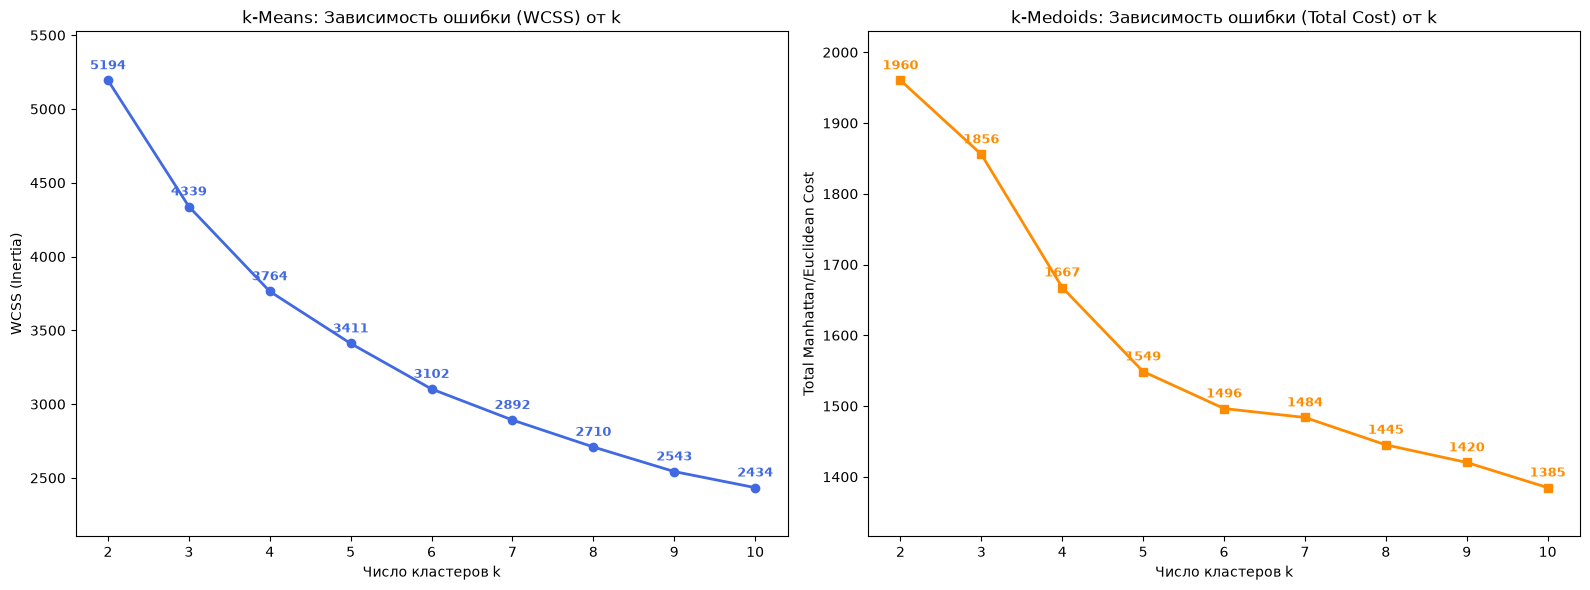

In [6]:
k_values = list(range(2, 11))
kmeans_errors = []
kmedoids_errors = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    kmeans_errors.append(km.inertia_)

    kmed = KMedoidsCustom(n_clusters=k, random_state=42).fit(X_scaled)
    kmedoids_errors.append(kmed.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(k_values, kmeans_errors, marker="o", color="royalblue", lw=2)
axes[0].set_title("k-Means: Зависимость ошибки (WCSS) от k")
axes[0].set_xlabel("Число кластеров k")
axes[0].set_ylabel("WCSS (Inertia)")
axes[0].set_xticks(k_values)

for x, y in zip(k_values, kmeans_errors):
    axes[0].annotate(
        f"{y:.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="royalblue",
    )

axes[0].margins(y=0.12)

axes[1].plot(k_values, kmedoids_errors, marker="s", color="darkorange", lw=2)
axes[1].set_title("k-Medoids: Зависимость ошибки (Total Cost) от k")
axes[1].set_xlabel("Число кластеров k")
axes[1].set_ylabel("Total Manhattan/Euclidean Cost")
axes[1].set_xticks(k_values)

for x, y in zip(k_values, kmedoids_errors):
    axes[1].annotate(
        f"{y:.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="darkorange",
    )

axes[1].margins(y=0.12)

plt.tight_layout()
plt.show()

## 7. Эксперименты с зашумлением данных

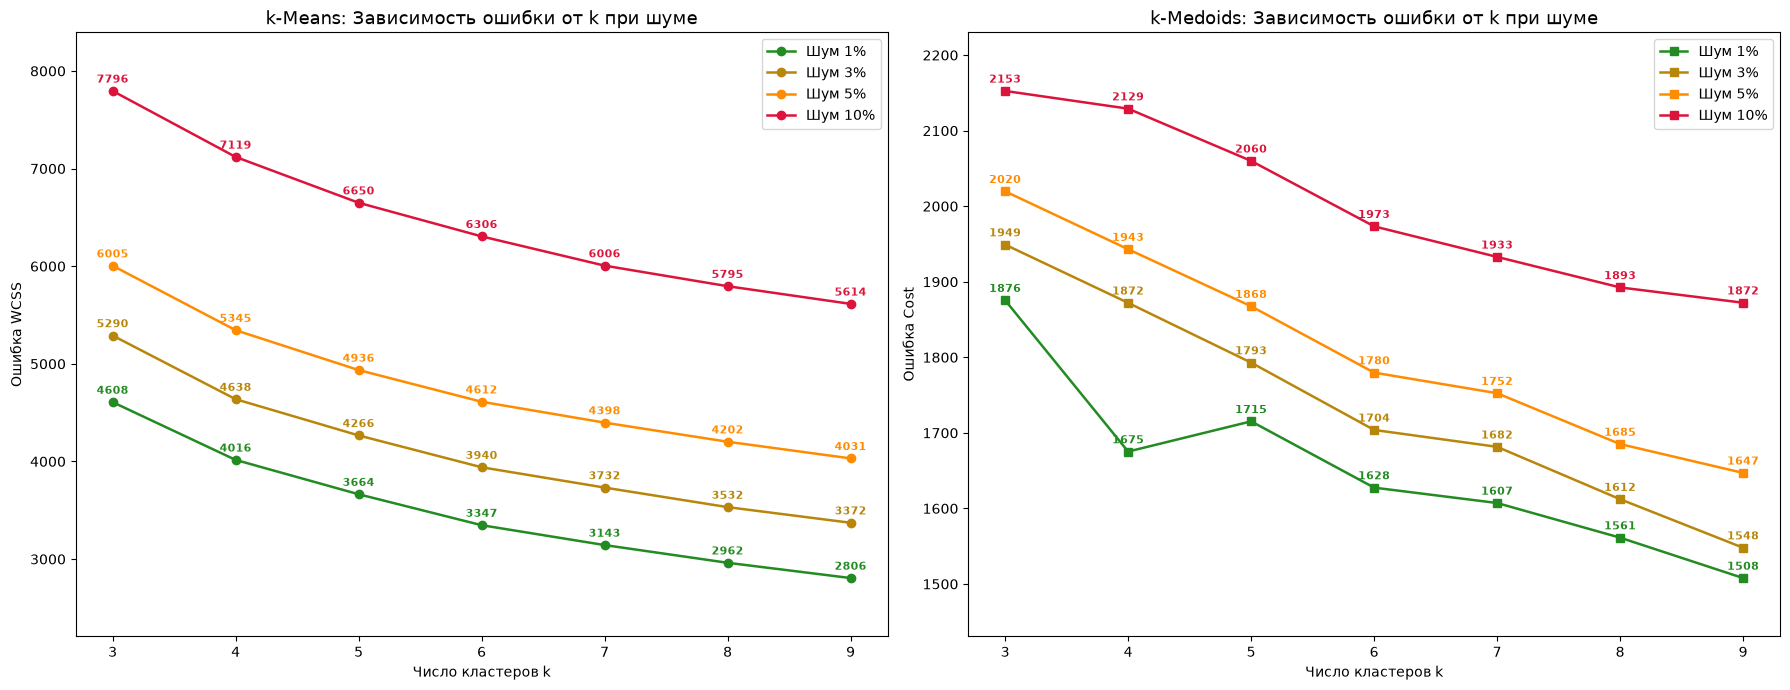

In [7]:
noise_ratios = [0.01, 0.03, 0.05, 0.10]
k_range = list(range(3, 10))

results_kmeans = {nr: [] for nr in noise_ratios}
results_kmedoids = {nr: [] for nr in noise_ratios}

for nr in noise_ratios:
    X_noisy = add_noise(X_scaled, noise_ratio=nr, noise_scale=4.0, random_state=42)

    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=5).fit(X_noisy)
        results_kmeans[nr].append(km.inertia_)

        kmed = KMedoidsCustom(n_clusters=k, random_state=42).fit(X_noisy)
        results_kmedoids[nr].append(kmed.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

colors = ["forestgreen", "darkgoldenrod", "darkorange", "crimson"]

for nr, color in zip(noise_ratios, colors):
    axes[0].plot(
        k_range,
        results_kmeans[nr],
        marker="o",
        label=f"Шум {int(nr * 100)}%",
        color=color,
        lw=1.8,
    )
    axes[1].plot(
        k_range,
        results_kmedoids[nr],
        marker="s",
        label=f"Шум {int(nr * 100)}%",
        color=color,
        lw=1.8,
    )

    for x, y in zip(k_range, results_kmeans[nr]):
        axes[0].annotate(
            f"{y:.0f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 6),
            ha="center",
            fontsize=8,
            fontweight="bold",
            color=color,
        )

    for x, y in zip(k_range, results_kmedoids[nr]):
        axes[1].annotate(
            f"{y:.0f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 6),
            ha="center",
            fontsize=8,
            fontweight="bold",
            color=color,
        )

axes[0].set_title("k-Means: Зависимость ошибки от k при шуме", fontsize=13)
axes[0].set_xlabel("Число кластеров k")
axes[0].set_ylabel("Ошибка WCSS")
axes[0].set_xticks(k_range)
axes[0].margins(y=0.12)
axes[0].legend(loc="upper right")

axes[1].set_title("k-Medoids: Зависимость ошибки от k при шуме", fontsize=13)
axes[1].set_xlabel("Число кластеров k")
axes[1].set_ylabel("Ошибка Cost")
axes[1].set_xticks(k_range)
axes[1].margins(y=0.12)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 8. Сравнительная визуализация влияния шума на геометрию кластеров (при 10% шума и k=4)

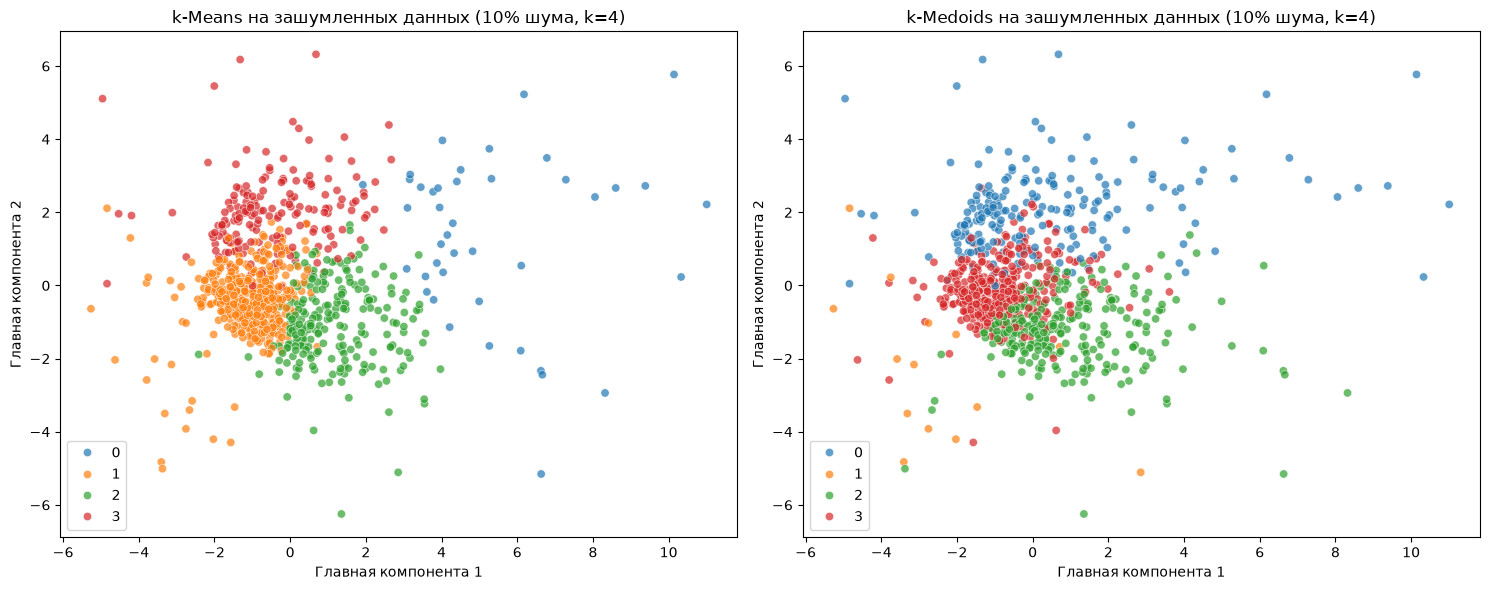

In [8]:
X_noisy_10 = add_noise(X_scaled, noise_ratio=0.10, noise_scale=4.0, random_state=42)

km_noisy = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_noisy_10)
kmed_noisy = KMedoidsCustom(n_clusters=4, random_state=42).fit(X_noisy_10)

X_noisy_pca = pca.transform(X_noisy_10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    x=X_noisy_pca[:, 0],
    y=X_noisy_pca[:, 1],
    hue=km_noisy.labels_,
    palette="tab10",
    ax=axes[0],
    alpha=0.7,
)
axes[0].set_title("k-Means на зашумленных данных (10% шума, k=4)")
axes[0].set_xlabel("Главная компонента 1")
axes[0].set_ylabel("Главная компонента 2")

sns.scatterplot(
    x=X_noisy_pca[:, 0],
    y=X_noisy_pca[:, 1],
    hue=kmed_noisy.labels_,
    palette="tab10",
    ax=axes[1],
    alpha=0.7,
)
axes[1].set_title("k-Medoids на зашумленных данных (10% шума, k=4)")
axes[1].set_xlabel("Главная компонента 1")
axes[1].set_ylabel("Главная компонента 2")

plt.tight_layout()
plt.show()

## 9. Выводы
В ходе работы были исследованы алгоритмы k-Means и k-Medoids на данных о клиентах банка при k 2-10 и уровне шума от 1% до 10%.

Основные результаты:
1. Оптимальное число кластеров: 
   - На чистых данных точка перегиба ("локоть") четко выражена в районе k = 4...6: 
     - У k-Means ошибка снижается с 5194 (k=2) до 3764 (k=4), после чего спад замедляется.
     - У k-Medoids основной спад завершается к k=5...6 (1549 -> 1496), где кривая выходит на плавное плато.
2. Влияние зашумления: 
   - С ростом доли шума ошибки закономерно растут у обоих алгоритмов по всем значениям $k$.
3. Устойчивость к выбросам (k-Means против k-Medoids):
   - k-Means крайне чувствителен к шуму: при k=4 ошибка WCSS возрастает с 4016 (при 1% шума) до 7119 (при 10% шума) — скачок более чем на 77% из-за квадратичного штрафа за расстояния.
   - k-Medoids показал высокую робастность: при том же k=4 суммарная ошибка Cost выросла всего с 1675 до 2129 (рост всего на 27%). Медоиды выбираются среди реальных точек ядра кластера, поэтому изолированные выбросы не смещают центры.
4. Практический итог: для чистых данных эффективнее использовать быстрый k-Means, а при наличии выбросов и шума в банковских данных предпочтителен робастный k-Medoids.